# Lab 5 — “Shout STOP!”: Voice Emergency Stop

**Aim:** Train a compact 3-class keyword-spotting model using Google Mini Speech Commands, MFCC features and a depthwise-separable CNN (DS-CNN), then export a full-INT8 TensorFlow Lite model.

**Classes:** `stop` = emergency word; `_unknown_` = clips from the other seven words; `_silence_` = 1-second background/noise-only clips.

**Workflow:** download → speaker-wise 80/10/10 split → 16 kHz/1 s preprocessing → 30 ms frames and 20 ms hop → 49 × 10 MFCC → train DS-CNN with augmentation → test misses and false alarms → compare Float32 and INT8 → export `kws_int8.tflite` and `kws_config.json`.

> **Noise-source note:** The provided Mini Speech Commands ZIP contains eight spoken-word folders, not a background-noise folder. For realistic factory noise, upload a 16 kHz WAV named `/content/factory_noise.wav` before running the noise-generation cell. If it is absent, the notebook creates low-level coloured-noise clips as a clearly labelled fallback. The fallback is suitable for demonstrating the pipeline but is not a substitute for real factory recordings.

The test voices are kept separate by speaker ID, not just by random file split. Model accuracy and model size are measured by the notebook; they are not assumed in advance.

## 1. Imports and configuration

In [1]:
import os, json, math, random, zipfile, time, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy.signal import resample_poly
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)
tf.keras.utils.set_random_seed(SEED)

SAMPLE_RATE = 16_000
CLIP_SAMPLES = SAMPLE_RATE          # exactly 1 second
FRAME_LENGTH = 480                  # 30 ms at 16 kHz
FRAME_STEP = 320                    # 20 ms at 16 kHz
FFT_LENGTH = 512
NUM_MEL_BINS = 40
NUM_MFCC = 10
EXPECTED_FRAMES = 49
LABELS = ["stop", "_unknown_", "_silence_"]
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}

OUTPUT_DIR = Path("/content/lab5_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
print("Audio: 16 kHz mono, 1 second; frame=30 ms, hop=20 ms; MFCC shape=(49, 10)")

TensorFlow: 2.21.0
GPU available: True
Audio: 16 kHz mono, 1 second; frame=30 ms, hop=20 ms; MFCC shape=(49, 10)


## 2. Download Mini Speech Commands

In [2]:
DATA_URL = "http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip"
DATA_ROOT = Path("/content/data")
DATA_DIR = DATA_ROOT / "mini_speech_commands"
DATA_ROOT.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.exists():
    zip_path = tf.keras.utils.get_file(
        fname="mini_speech_commands.zip",
        origin=DATA_URL,
        cache_dir="/content",
        cache_subdir="downloads",
        extract=False,
    )
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_ROOT)

# Find the extracted directory automatically in case the ZIP nesting changes.
if not DATA_DIR.exists():
    matches = list(DATA_ROOT.rglob("stop"))
    matches = [p for p in matches if p.is_dir() and any(p.glob("*.wav"))]
    if matches:
        DATA_DIR = matches[0].parent

assert DATA_DIR.exists(), f"Could not find extracted dataset under {DATA_ROOT}"
records = []
for wav_path in sorted(DATA_DIR.glob("*/*.wav")):
    word = wav_path.parent.name
    if word not in {"down", "go", "left", "no", "right", "stop", "up", "yes"}:
        continue
    # Speech Commands names identify a speaker before '_nohash_'.
    speaker_id = wav_path.stem.split("_nohash_")[0]
    records.append({"path": str(wav_path), "word": word, "speaker_id": speaker_id})

all_words = sorted({r["word"] for r in records})
print("Dataset folder:", DATA_DIR)
print("Word folders found:", all_words)
print("Audio files:", len(records))
assert set(all_words) == {"down", "go", "left", "no", "right", "stop", "up", "yes"}, \
    "Expected the eight Mini Speech Commands word folders."
pd.Series([r["word"] for r in records]).value_counts().sort_index().to_frame("clips")

182082353/182082353 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dataset folder: /content/data/mini_speech_commands
Word folders found: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
Audio files: 8000


,clips
down,1000
go,1000
left,1000
no,1000
right,1000
stop,1000
up,1000
yes,1000


## 3. Split speakers first, then create balanced classes

In [3]:
# Assign each speaker to exactly one split. All their clips follow that assignment.
speakers = sorted({r["speaker_id"] for r in records})
rng.shuffle(speakers)
n_speakers = len(speakers)
n_train = max(1, int(0.80 * n_speakers))
n_val = max(1, int(0.10 * n_speakers))
if n_train + n_val >= n_speakers:
    n_train = max(1, n_speakers - 2)
    n_val = 1
speaker_split = {}
for s in speakers[:n_train]: speaker_split[s] = "train"
for s in speakers[n_train:n_train+n_val]: speaker_split[s] = "validation"
for s in speakers[n_train+n_val:]: speaker_split[s] = "test"

for r in records:
    r["split"] = speaker_split[r["speaker_id"]]

split_speaker_sets = {sp: {r["speaker_id"] for r in records if r["split"] == sp}
                      for sp in ["train", "validation", "test"]}
assert split_speaker_sets["train"].isdisjoint(split_speaker_sets["validation"])
assert split_speaker_sets["train"].isdisjoint(split_speaker_sets["test"])
assert split_speaker_sets["validation"].isdisjoint(split_speaker_sets["test"])

# Use every STOP clip in each split. Sample the same count of unknown-word clips
# from the other seven words in the SAME speaker split. Create equal-count noise clips.
split_records = {}
for split_name in ["train", "validation", "test"]:
    split_source = [r for r in records if r["split"] == split_name]
    stop_rows = [r for r in split_source if r["word"] == "stop"]
    unknown_pool = [r for r in split_source if r["word"] != "stop"]
    if not stop_rows:
        raise ValueError(f"No STOP clips in {split_name}; adjust speaker split seed/proportions.")
    if len(unknown_pool) < len(stop_rows):
        raise ValueError(f"Not enough other-word clips in {split_name} to balance STOP.")
    chosen_unknown_idx = rng.choice(len(unknown_pool), size=len(stop_rows), replace=False)
    unknown_rows = [unknown_pool[i] for i in chosen_unknown_idx]
    selected = []
    for r in stop_rows:
        selected.append({"path": r["path"], "label": "stop", "speaker_id": r["speaker_id"], "split": split_name})
    for r in unknown_rows:
        selected.append({"path": r["path"], "label": "_unknown_", "speaker_id": r["speaker_id"], "split": split_name})
    for i in range(len(stop_rows)):
        selected.append({"path": None, "label": "_silence_", "speaker_id": "noise", "split": split_name})
    split_records[split_name] = selected

balance_rows = []
for split_name, rows in split_records.items():
    counts = pd.Series([r["label"] for r in rows]).value_counts()
    for label in LABELS:
        balance_rows.append({"split": split_name, "class": label, "clips": int(counts.get(label, 0))})
balance_table = pd.DataFrame(balance_rows)
print("Unique speakers:", n_speakers)
print("Speaker counts by split:", {k: len(v) for k, v in split_speaker_sets.items()})
print("Balanced original examples (before train-time augmentation):")
display(balance_table.pivot(index="split", columns="class", values="clips").reindex(["train", "validation", "test"]))
balance_table.to_csv(OUTPUT_DIR / "balanced_dataset_counts.csv", index=False)

Unique speakers: 1750
Speaker counts by split: {'train': 1400, 'validation': 175, 'test': 175}
Balanced original examples (before train-time augmentation):


class,_silence_,_unknown_,stop
split,,,
train,795,795,795
validation,98,98,98
test,107,107,107


## 4. Audio loading, background noise and MFCC extraction

If you have a real machine/factory ambience recording, upload it to Colab as `/content/factory_noise.wav` **before executing this cell**. It should be a WAV file. The helper resamples it to 16 kHz if needed. Otherwise, generated coloured noise is used for the `_silence_` class.

In [4]:
def load_wav(path, exact_one_second=True):
    """Read WAV as mono float32 and resample to 16 kHz if necessary."""
    data = tf.io.read_file(str(path))
    audio, sample_rate = tf.audio.decode_wav(data, desired_channels=1)
    wave = audio.numpy().squeeze().astype(np.float32)
    sr = int(sample_rate.numpy())
    if sr != SAMPLE_RATE:
        g = math.gcd(sr, SAMPLE_RATE)
        wave = resample_poly(wave, SAMPLE_RATE // g, sr // g).astype(np.float32)
    if exact_one_second:
        if len(wave) < CLIP_SAMPLES:
            wave = np.pad(wave, (0, CLIP_SAMPLES - len(wave)))
        else:
            wave = wave[:CLIP_SAMPLES]
    return wave.astype(np.float32)

FACTORY_NOISE_PATH = Path("/content/factory_noise.wav")
background_source = None
if FACTORY_NOISE_PATH.exists():
    background_source = load_wav(FACTORY_NOISE_PATH, exact_one_second=False)
    print("Using uploaded background recording:", FACTORY_NOISE_PATH)
else:
    print("No factory_noise.wav found: using generated coloured-noise fallback.")


def make_noise_clip():
    """Create a 1-second noise clip, using real ambient audio when provided."""
    if background_source is not None and len(background_source) >= CLIP_SAMPLES:
        max_start = len(background_source) - CLIP_SAMPLES
        start = int(rng.integers(0, max_start + 1))
        noise = background_source[start:start + CLIP_SAMPLES].copy()
        noise -= noise.mean()
        rms = np.sqrt(np.mean(noise ** 2)) + 1e-8
        noise *= float(rng.uniform(0.003, 0.04)) / rms
    else:
        # Fallback only: mix high-frequency noise with a slowly varying component.
        white = rng.normal(size=CLIP_SAMPLES)
        slow_points = rng.normal(size=256)
        slow = np.interp(np.linspace(0, 255, CLIP_SAMPLES), np.arange(256), slow_points)
        noise = 0.7 * white + 0.3 * slow
        noise -= noise.mean()
        rms = np.sqrt(np.mean(noise ** 2)) + 1e-8
        noise *= float(rng.uniform(0.003, 0.02)) / rms
    return np.clip(noise, -1.0, 1.0).astype(np.float32)

MEL_MATRIX = tf.signal.linear_to_mel_weight_matrix(
    num_mel_bins=NUM_MEL_BINS,
    num_spectrogram_bins=FFT_LENGTH // 2 + 1,
    sample_rate=SAMPLE_RATE,
    lower_edge_hertz=20.0,
    upper_edge_hertz=7600.0,
)

def wave_to_mfcc(wave):
    wave = tf.convert_to_tensor(wave, dtype=tf.float32)
    stft = tf.signal.stft(
        wave, frame_length=FRAME_LENGTH, frame_step=FRAME_STEP,
        fft_length=FFT_LENGTH, window_fn=tf.signal.hann_window, pad_end=False
    )
    power = tf.square(tf.abs(stft))
    mel_power = tf.matmul(power, MEL_MATRIX)
    log_mel = tf.math.log(mel_power + 1e-6)
    mfcc = tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :NUM_MFCC]
    mfcc = mfcc.numpy().astype(np.float32)
    assert mfcc.shape == (EXPECTED_FRAMES, NUM_MFCC), mfcc.shape
    return mfcc


def augment_wave(wave):
    """Random time shift (up to 100 ms) plus additive background-like noise."""
    shift = int(rng.integers(-1600, 1601))
    shifted = np.zeros_like(wave)
    if shift > 0:
        shifted[shift:] = wave[:-shift]
    elif shift < 0:
        shifted[:shift] = wave[-shift:]
    else:
        shifted[:] = wave
    noise = make_noise_clip()
    noise_rms = np.sqrt(np.mean(noise ** 2)) + 1e-8
    speech_rms = np.sqrt(np.mean(shifted ** 2)) + 1e-8
    snr_db = float(rng.uniform(8.0, 25.0))
    noise = noise * (speech_rms / (noise_rms * (10 ** (snr_db / 20.0))))
    return np.clip(shifted + noise, -1.0, 1.0).astype(np.float32)

# Verify the required frame count and MFCC dimensions.
_demo_wave = load_wav(next(r["path"] for r in records if r["word"] == "stop"))
_demo_mfcc = wave_to_mfcc(_demo_wave)
print("Wave samples:", len(_demo_wave), "| duration:", len(_demo_wave) / SAMPLE_RATE, "s")
print("MFCC shape (frames, coefficients):", _demo_mfcc.shape)

No factory_noise.wav found: using generated coloured-noise fallback.
Wave samples: 16000 | duration: 1.0 s
MFCC shape (frames, coefficients): (49, 10)


## 5. Plot what the model hears: waveform, spectrogram and MFCC

The spectrogram shows energy across frequency over time. MFCCs compress the spectral envelope into 10 coefficients per frame, making the model's input smaller than a raw waveform.

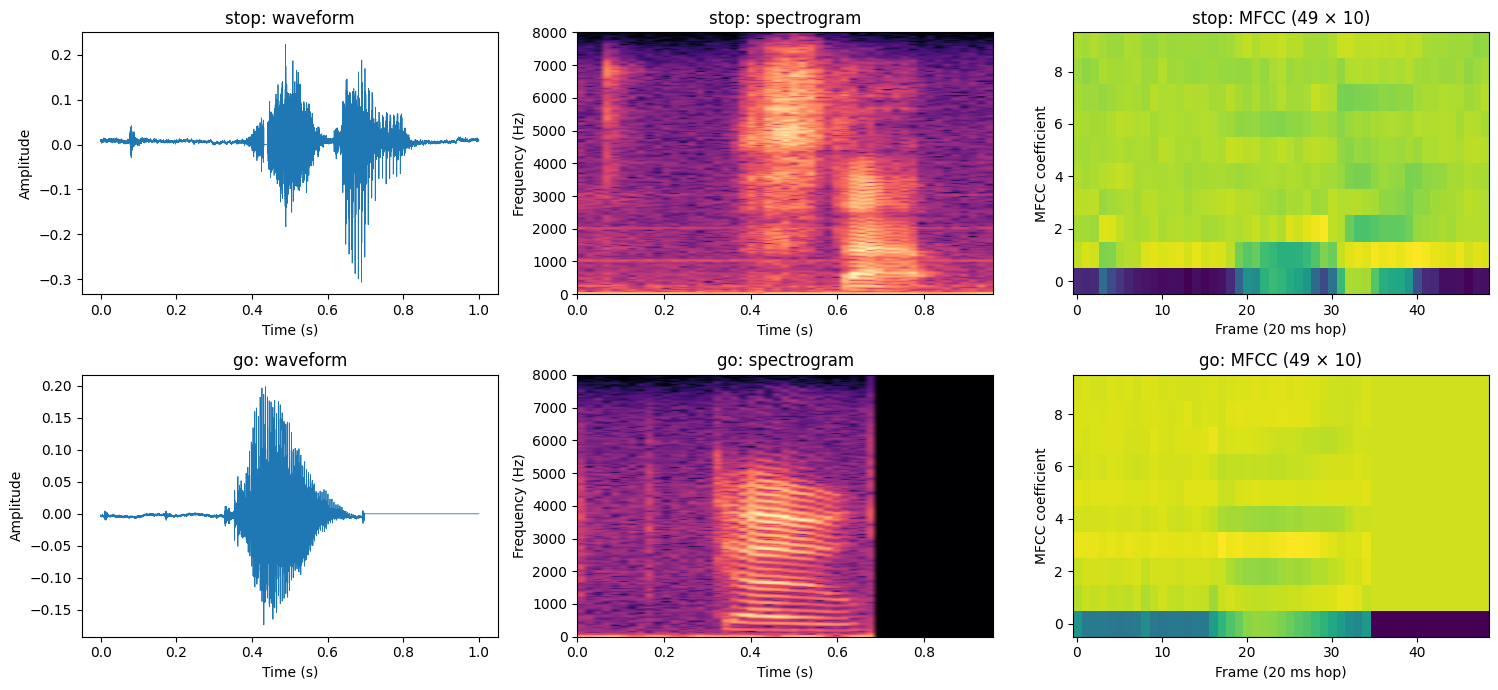

In [5]:
plot_records = {}
for word in ["stop", "go"]:
    candidates = [r for r in records if r["word"] == word and r["split"] == "train"]
    if not candidates:
        candidates = [r for r in records if r["word"] == word]
    plot_records[word] = candidates[0]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, word in enumerate(["stop", "go"]):
    wave = load_wav(plot_records[word]["path"])
    mfcc = wave_to_mfcc(wave)
    time_axis = np.arange(len(wave)) / SAMPLE_RATE
    axes[row, 0].plot(time_axis, wave, linewidth=0.6)
    axes[row, 0].set_title(f'{word}: waveform')
    axes[row, 0].set_xlabel("Time (s)")
    axes[row, 0].set_ylabel("Amplitude")

    stft = tf.signal.stft(
        wave, frame_length=FRAME_LENGTH, frame_step=FRAME_STEP,
        fft_length=FFT_LENGTH, window_fn=tf.signal.hann_window, pad_end=False
    )
    spec_db = 10.0 * np.log10(np.square(np.abs(stft.numpy())).T + 1e-8)
    axes[row, 1].imshow(
        spec_db, origin="lower", aspect="auto",
        extent=[0, (EXPECTED_FRAMES - 1) * FRAME_STEP / SAMPLE_RATE, 0, SAMPLE_RATE / 2],
        cmap="magma"
    )
    axes[row, 1].set_title(f'{word}: spectrogram')
    axes[row, 1].set_xlabel("Time (s)")
    axes[row, 1].set_ylabel("Frequency (Hz)")

    axes[row, 2].imshow(mfcc.T, origin="lower", aspect="auto", cmap="viridis")
    axes[row, 2].set_title(f'{word}: MFCC (49 × 10)')
    axes[row, 2].set_xlabel("Frame (20 ms hop)")
    axes[row, 2].set_ylabel("MFCC coefficient")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "waveform_spectrogram_mfcc_stop_go.png", dpi=160, bbox_inches="tight")
plt.show()

**Three-line explanation for the report:**
1. “Stop” and “go” have different consonants and vowel sounds, so their energy patterns differ over time.
2. The spectrogram displays those changing frequency-energy patterns; MFCCs summarise the spectral envelope in each short frame.
3. The resulting MFCC patterns can help a classifier separate the words, but plots alone do not prove reliable emergency-stop performance.

## 6. Extract balanced MFCC datasets and augment training data

In [6]:
def process_split(split_name, augment_training=False):
    features, labels, meta = [], [], []
    for item in split_records[split_name]:
        if item["label"] == "_silence_":
            wave = make_noise_clip()
        else:
            wave = load_wav(item["path"])
        features.append(wave_to_mfcc(wave))
        labels.append(LABEL_TO_ID[item["label"]])
        meta.append({"split": split_name, "label": item["label"],
                     "speaker_id": item["speaker_id"], "augmented": False})

        if augment_training:
            if item["label"] in ("stop", "_unknown_"):
                aug_wave = augment_wave(wave)
            else:
                # A different noise-only segment keeps the three training classes balanced.
                aug_wave = make_noise_clip()
            features.append(wave_to_mfcc(aug_wave))
            labels.append(LABEL_TO_ID[item["label"]])
            meta.append({"split": split_name, "label": item["label"],
                         "speaker_id": item["speaker_id"], "augmented": True})

    return np.stack(features).astype(np.float32), np.asarray(labels, dtype=np.int64), meta

X_train_raw, y_train, meta_train = process_split("train", augment_training=True)
X_val_raw, y_val, meta_val = process_split("validation", augment_training=False)
X_test_raw, y_test, meta_test = process_split("test", augment_training=False)

# Fit normalisation statistics only on training features; reuse them on val/test.
feature_mean = X_train_raw.mean(axis=(0, 1), keepdims=True)
feature_std = X_train_raw.std(axis=(0, 1), keepdims=True) + 1e-6
X_train = ((X_train_raw - feature_mean) / feature_std)[..., np.newaxis].astype(np.float32)
X_val = ((X_val_raw - feature_mean) / feature_std)[..., np.newaxis].astype(np.float32)
X_test = ((X_test_raw - feature_mean) / feature_std)[..., np.newaxis].astype(np.float32)

print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)
print("Training class counts after augmentation:",
      {LABELS[i]: int(np.sum(y_train == i)) for i in range(3)})
print("Validation class counts:", {LABELS[i]: int(np.sum(y_val == i)) for i in range(3)})
print("Test class counts:", {LABELS[i]: int(np.sum(y_test == i)) for i in range(3)})
assert X_train.shape[1:] == (49, 10, 1)

# Export a processed dataset CSV. Features are normalised with TRAIN-only statistics.
def feature_frame(X, y, meta):
    flat = X.reshape(len(X), -1)
    columns = [f"frame{t:02d}_mfcc{c:02d}" for t in range(EXPECTED_FRAMES) for c in range(NUM_MFCC)]
    df = pd.DataFrame(flat, columns=columns)
    df.insert(0, "augmented", [m["augmented"] for m in meta])
    df.insert(0, "speaker_id", [m["speaker_id"] for m in meta])
    df.insert(0, "split", [m["split"] for m in meta])
    df.insert(0, "label", [LABELS[int(i)] for i in y])
    return df

processed_df = pd.concat([
    feature_frame(X_train, y_train, meta_train),
    feature_frame(X_val, y_val, meta_val),
    feature_frame(X_test, y_test, meta_test),
], ignore_index=True)
processed_csv = OUTPUT_DIR / "kws_mfcc_dataset.csv"
processed_df.to_csv(processed_csv, index=False)
print("Saved processed features:", processed_csv, "| rows:", len(processed_df), "| columns:", len(processed_df.columns))

X_train: (4770, 49, 10, 1) X_val: (294, 49, 10, 1) X_test: (321, 49, 10, 1)
Training class counts after augmentation: {'stop': 1590, '_unknown_': 1590, '_silence_': 1590}
Validation class counts: {'stop': 98, '_unknown_': 98, '_silence_': 98}
Test class counts: {'stop': 107, '_unknown_': 107, '_silence_': 107}
Saved processed features: /content/lab5_outputs/kws_mfcc_dataset.csv | rows: 5385 | columns: 494


## 7. Build and train the DS-CNN

In [7]:
def ds_block(x, filters, stride=(1, 1), name="ds"):
    x = tf.keras.layers.DepthwiseConv2D(
        kernel_size=3, strides=stride, padding="same", use_bias=False,
        name=f"{name}_depthwise"
    )(x)
    x = tf.keras.layers.BatchNormalization(name=f"{name}_dw_bn")(x)
    x = tf.keras.layers.ReLU(max_value=6.0, name=f"{name}_dw_relu")(x)
    x = tf.keras.layers.Conv2D(
        filters, kernel_size=1, padding="same", use_bias=False,
        name=f"{name}_pointwise"
    )(x)
    x = tf.keras.layers.BatchNormalization(name=f"{name}_pw_bn")(x)
    x = tf.keras.layers.ReLU(max_value=6.0, name=f"{name}_pw_relu")(x)
    return x

inputs = tf.keras.Input(shape=(EXPECTED_FRAMES, NUM_MFCC, 1), name="mfcc_input")
x = tf.keras.layers.Conv2D(32, 3, strides=(2, 1), padding="same", use_bias=False, name="stem_conv")(inputs)
x = tf.keras.layers.BatchNormalization(name="stem_bn")(x)
x = tf.keras.layers.ReLU(max_value=6.0, name="stem_relu")(x)
x = ds_block(x, 64, stride=(2, 1), name="ds1")
x = ds_block(x, 96, stride=(2, 2), name="ds2")
x = ds_block(x, 128, stride=(2, 1), name="ds3")
x = ds_block(x, 128, stride=(1, 1), name="ds4")
x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
outputs = tf.keras.layers.Dense(3, activation="softmax", name="class_probabilities")(x)
model = tf.keras.Model(inputs, outputs, name="shout_stop_ds_cnn")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()
print("Trainable + non-trainable parameters:", model.count_params())
print("Approx. raw INT8 parameter storage (not final TFLite size):", round(model.count_params() / 1024, 1), "KB")

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
]
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)
model.save(OUTPUT_DIR / "kws_float32.keras")

Model: "shout_stop_ds_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mfcc_input (InputLayer)         │ (None, 49, 10, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 25, 10, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_bn (BatchNormalization)    │ (None, 25, 10, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_relu (ReLU)                │ (None, 25, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_depthwise (DepthwiseConv2D) │ (None, 13, 10, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_dw_bn (BatchNormalization)  │ (None, 13, 10, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_dw_relu (ReLU)              │ (None, 13, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_pointwise (Conv2D)          │ (None, 13, 10, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_pw_bn (BatchNormalization)  │ (None, 13, 10, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_pw_relu (ReLU)              │ (None, 13, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_depthwise (DepthwiseConv2D) │ (None, 7, 5, 64)       │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_dw_bn (BatchNormalization)  │ (None, 7, 5, 64)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_dw_relu (ReLU)              │ (None, 7, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_pointwise (Conv2D)          │ (None, 7, 5, 96)       │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_pw_bn (BatchNormalization)  │ (None, 7, 5, 96)       │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_pw_relu (ReLU)              │ (None, 7, 5, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_depthwise (DepthwiseConv2D) │ (None, 4, 5, 96)       │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_dw_bn (BatchNormalization)  │ (None, 4, 5, 96)       │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_dw_relu (ReLU)              │ (None, 4, 5, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_pointwise (Conv2D)          │ (None, 4, 5, 128)      │        12,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_pw_bn (BatchNormalization)  │ (None, 4, 5, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_pw_relu (ReLU)              │ (None, 4, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds4_depthwise (DepthwiseConv2D) │ (None, 4, 5, 128)      │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds4_dw_bn (BatchNormalization)  │ (None, 4, 5, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds4_dw_relu (ReLU)              │ (None, 4, 5, 128)      │             

 Total params: 43,491 (169.89 KB)

 Trainable params: 41,955 (163.89 KB)

 Non-trainable params: 1,536 (6.00 KB)

Trainable + non-trainable parameters: 43491
Approx. raw INT8 parameter storage (not final TFLite size): 42.5 KB
Epoch 1/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.8134 - loss: 0.4069 - val_accuracy: 0.3333 - val_loss: 1.6588 - learning_rate: 0.0010
Epoch 2/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9226 - loss: 0.1841 - val_accuracy: 0.3333 - val_loss: 2.4221 - learning_rate: 0.0010
Epoch 3/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9612 - loss: 0.1011 - val_accuracy: 0.8231 - val_loss: 0.4753 - learning_rate: 0.0010
Epoch 4/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9816 - loss: 0.0569 - val_accuracy: 0.9422 - val_loss: 0.1565 - learning_rate: 0.0010
Epoch 5/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9925 - loss: 0.0326 - val_accuracy: 0.9456 - val_loss: 0.1426 - learning_rate: 0.0010
Epoch 6/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9927 - loss: 0.0244 - val_accuracy: 0.9184 - val_loss: 0.453

## 8. Plot training curves

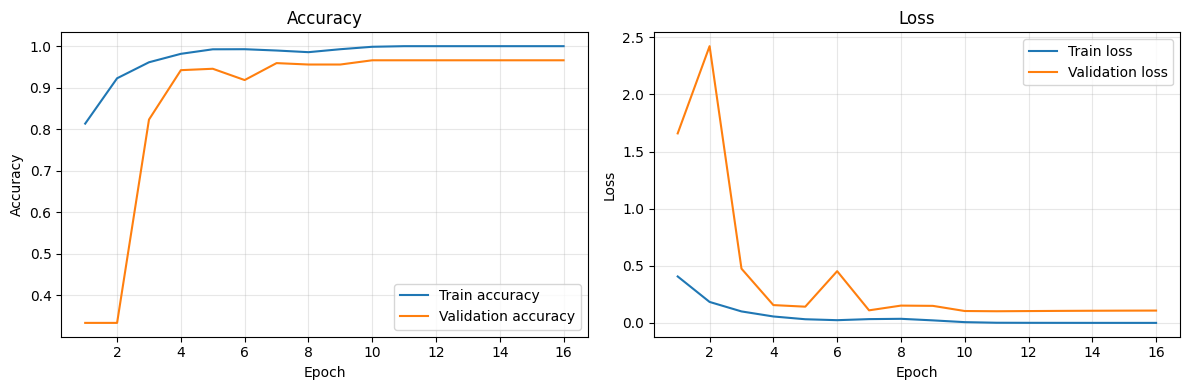

In [8]:
h = history.history
epochs = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, h["accuracy"], label="Train accuracy")
axes[0].plot(epochs, h["val_accuracy"], label="Validation accuracy")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[0].set_title("Accuracy")
axes[1].plot(epochs, h["loss"], label="Train loss")
axes[1].plot(epochs, h["val_loss"], label="Validation loss")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
axes[1].set_title("Loss")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Test evaluation: confusion matrix, misses and false alarms

Float32 Keras test accuracy: 0.9533 (95.33%)
              precision    recall  f1-score   support

        stop       0.94      0.92      0.93       107
   _unknown_       0.92      0.94      0.93       107
   _silence_       1.00      1.00      1.00       107

    accuracy                           0.95       321
   macro avg       0.95      0.95      0.95       321
weighted avg       0.95      0.95      0.95       321



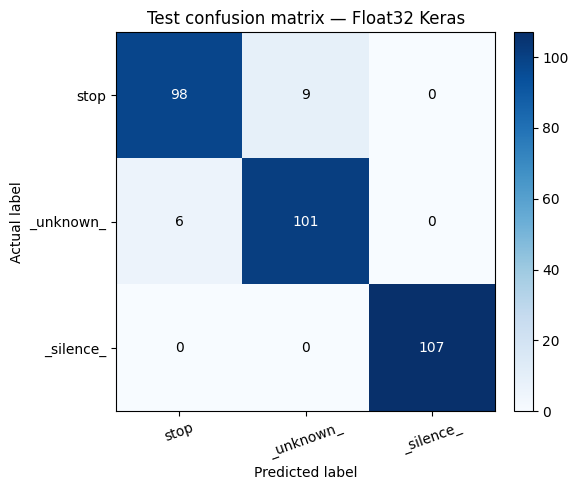

STOP misses (actual STOP predicted as another class): 9/107 (8.41%)
False alarms (actual non-STOP predicted as STOP): 6/214 (2.80%)
Safety interpretation: misses can leave the belt running; false alarms can halt production unnecessarily.


In [9]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
test_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(test_prob, axis=1)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

print(f"Float32 Keras test accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
print(classification_report(y_test, y_pred, labels=[0, 1, 2], target_names=LABELS, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), LABELS, rotation=20)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label")
ax.set_title("Test confusion matrix — Float32 Keras")
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() * 0.55 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_float32.png", dpi=160, bbox_inches="tight")
plt.show()

# Rows are actual labels; columns are predicted labels.
stop_misses = int(cm[0, 1:].sum())
actual_stop = int(cm[0, :].sum())
false_alarms = int(cm[1:, 0].sum())
actual_non_stop = int(cm[1:, :].sum())
miss_rate = stop_misses / max(actual_stop, 1)
false_alarm_rate = false_alarms / max(actual_non_stop, 1)
print(f"STOP misses (actual STOP predicted as another class): {stop_misses}/{actual_stop} ({miss_rate:.2%})")
print(f"False alarms (actual non-STOP predicted as STOP): {false_alarms}/{actual_non_stop} ({false_alarm_rate:.2%})")
print("Safety interpretation: misses can leave the belt running; false alarms can halt production unnecessarily.")

## 10. Convert to Float32 and full-INT8 TensorFlow Lite

In [10]:
# Float32 TFLite baseline.
converter_float = tf.lite.TFLiteConverter.from_keras_model(model)
float_tflite = converter_float.convert()
float_path = OUTPUT_DIR / "kws_float32.tflite"
float_path.write_bytes(float_tflite)

# Full integer post-training quantization. Representative samples are TRAIN inputs only.
# Labels are not used for calibration.
def representative_dataset():
    n = min(200, len(X_train))
    chosen = np.linspace(0, len(X_train) - 1, n, dtype=int)
    for i in chosen:
        yield [X_train[i:i+1].astype(np.float32)]

converter_int8 = tf.lite.TFLiteConverter.from_keras_model(model)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_dataset
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_int8.inference_input_type = tf.int8
converter_int8.inference_output_type = tf.int8
int8_tflite = converter_int8.convert()
int8_path = OUTPUT_DIR / "kws_int8.tflite"
int8_path.write_bytes(int8_tflite)

print("Saved:", float_path, f"({float_path.stat().st_size/1024:.1f} KB)")
print("Saved:", int8_path, f"({int8_path.stat().st_size/1024:.1f} KB)")
print("INT8 file under 100 KB:", int8_path.stat().st_size < 100 * 1024)

Saved artifact at '/tmp/tmpgek4j3ol'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 10, 1), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140639964692112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637240094224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637240094032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637240096720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637240098064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637240088272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637239527568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637239527760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637240082512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637239526800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140637239526992: T

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


## 11. Compare Float32 vs INT8 on the same test set

In [11]:
def tflite_predict(model_path, X):
    interpreter = tf.lite.Interpreter(model_path=str(model_path), num_threads=1)
    interpreter.allocate_tensors()
    input_info = interpreter.get_input_details()[0]
    output_info = interpreter.get_output_details()[0]
    input_index = input_info["index"]
    output_index = output_info["index"]
    input_dtype = input_info["dtype"]
    output_dtype = output_info["dtype"]
    input_scale, input_zero = input_info["quantization"]
    output_scale, output_zero = output_info["quantization"]

    probabilities, elapsed_ms = [], []
    for sample in X:
        x = sample[np.newaxis, ...].astype(np.float32)
        if input_dtype == np.int8:
            if input_scale == 0:
                raise ValueError("INT8 input scale is zero; input quantization details are invalid.")
            x = np.clip(np.round(x / input_scale + input_zero), -128, 127).astype(np.int8)
        elif input_dtype == np.uint8:
            x = np.clip(np.round(x / input_scale + input_zero), 0, 255).astype(np.uint8)
        else:
            x = x.astype(input_dtype)

        start = time.perf_counter()
        interpreter.set_tensor(input_index, x)
        interpreter.invoke()
        raw = interpreter.get_tensor(output_index)
        elapsed_ms.append((time.perf_counter() - start) * 1000)

        if output_dtype in (np.int8, np.uint8):
            raw = (raw.astype(np.float32) - output_zero) * output_scale
        probabilities.append(raw.squeeze().astype(np.float32))

    return np.asarray(probabilities), float(np.mean(elapsed_ms))

float_prob_tflite, float_ms = tflite_predict(float_path, X_test)
int8_prob_tflite, int8_ms = tflite_predict(int8_path, X_test)
float_pred_tflite = float_prob_tflite.argmax(axis=1)
int8_pred_tflite = int8_prob_tflite.argmax(axis=1)
float_tflite_acc = accuracy_score(y_test, float_pred_tflite)
int8_tflite_acc = accuracy_score(y_test, int8_pred_tflite)

comparison = pd.DataFrame([
    {"Model": "Float32 TFLite", "Size (KB)": float_path.stat().st_size / 1024,
     "Test accuracy (%)": float_tflite_acc * 100, "Host invoke time (ms/sample)": float_ms},
    {"Model": "Full INT8 TFLite", "Size (KB)": int8_path.stat().st_size / 1024,
     "Test accuracy (%)": int8_tflite_acc * 100, "Host invoke time (ms/sample)": int8_ms},
])
display(comparison.round(3))
comparison.to_csv(OUTPUT_DIR / "float_vs_int8_comparison.csv", index=False)
print(f"Accuracy difference (Float32 - INT8): {(float_tflite_acc - int8_tflite_acc)*100:.2f} percentage points")
if int8_path.stat().st_size >= 100 * 1024:
    print("WARNING: INT8 model is not under 100 KB. Reduce DS-CNN channel counts and reconvert.")
else:
    print("Size target met: INT8 TFLite file is under 100 KB.")
print("Latency is measured in this Colab Python runtime, not on the target microcontroller.")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,Model,Size (KB),Test accuracy (%),Host invoke time (ms/sample)
0,Float32 TFLite,169.918,95.327,0.033
1,Full INT8 TFLite,70.508,95.327,0.069


Accuracy difference (Float32 - INT8): 0.00 percentage points
Size target met: INT8 TFLite file is under 100 KB.
Latency is measured in this Colab Python runtime, not on the target microcontroller.


## 12. INT8 confusion matrix and safety metrics

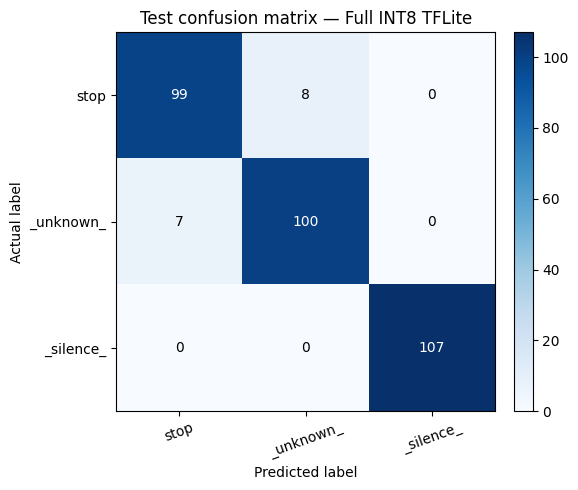

INT8 STOP misses: 8/107
INT8 false alarms: 7/214
              precision    recall  f1-score   support

        stop       0.93      0.93      0.93       107
   _unknown_       0.93      0.93      0.93       107
   _silence_       1.00      1.00      1.00       107

    accuracy                           0.95       321
   macro avg       0.95      0.95      0.95       321
weighted avg       0.95      0.95      0.95       321



In [12]:
cm_int8 = confusion_matrix(y_test, int8_pred_tflite, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_int8, cmap="Blues")
ax.set_xticks(range(3), LABELS, rotation=20)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label")
ax.set_title("Test confusion matrix — Full INT8 TFLite")
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(cm_int8[i, j]), ha="center", va="center",
                color="white" if cm_int8[i, j] > cm_int8.max() * 0.55 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_int8.png", dpi=160, bbox_inches="tight")
plt.show()

int8_stop_misses = int(cm_int8[0, 1:].sum())
int8_false_alarms = int(cm_int8[1:, 0].sum())
print(f"INT8 STOP misses: {int8_stop_misses}/{int(cm_int8[0, :].sum())}")
print(f"INT8 false alarms: {int8_false_alarms}/{int(cm_int8[1:, :].sum())}")
print(classification_report(y_test, int8_pred_tflite, labels=[0, 1, 2], target_names=LABELS, zero_division=0))

## 13. Export `kws_config.json` and package the outputs

In [13]:
# Store preprocessing, class order, normalization and quantization metadata for Lab 6.
int8_interpreter = tf.lite.Interpreter(model_path=str(int8_path), num_threads=1)
int8_interpreter.allocate_tensors()
in_detail = int8_interpreter.get_input_details()[0]
out_detail = int8_interpreter.get_output_details()[0]

config = {
    "project": "Lab 5 - Shout STOP!",
    "sample_rate_hz": SAMPLE_RATE,
    "channels": 1,
    "clip_samples": CLIP_SAMPLES,
    "clip_seconds": 1.0,
    "frame_length_samples": FRAME_LENGTH,
    "frame_length_ms": 30,
    "frame_step_samples": FRAME_STEP,
    "frame_step_ms": 20,
    "fft_length": FFT_LENGTH,
    "mel_bins": NUM_MEL_BINS,
    "mfcc_coefficients": NUM_MFCC,
    "mfcc_shape_frames_coefficients": [EXPECTED_FRAMES, NUM_MFCC],
    "classes_in_output_order": LABELS,
    "normalization": {
        "method": "MFCC standardization with training-set mean and standard deviation",
        "mean_by_mfcc_coefficient": feature_mean.reshape(-1).astype(float).tolist(),
        "std_by_mfcc_coefficient": feature_std.reshape(-1).astype(float).tolist()
    },
    "model_architecture": "DS-CNN with depthwise-separable convolution blocks, global average pooling and 3-way softmax",
    "model_file": "kws_int8.tflite",
    "input_dtype": np.dtype(in_detail["dtype"]).name,
    "input_scale": float(in_detail["quantization"][0]),
    "input_zero_point": int(in_detail["quantization"][1]),
    "output_dtype": np.dtype(out_detail["dtype"]).name,
    "output_scale": float(out_detail["quantization"][0]),
    "output_zero_point": int(out_detail["quantization"][1]),
    "int8_size_bytes": int(int8_path.stat().st_size),
    "int8_size_kb": round(int8_path.stat().st_size / 1024, 3),
    "target_size_kb": 100,
    "stop_threshold_note": "This notebook uses 3-class argmax. Tune a STOP decision threshold on validation data before real deployment.",
    "noise_source_used": "factory_noise.wav" if background_source is not None else "generated coloured-noise fallback"
}
config_path = OUTPUT_DIR / "kws_config.json"
config_path.write_text(json.dumps(config, indent=2))

print("Config saved:", config_path)
print("Export folder contents:")
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name:42s} {p.stat().st_size/1024:8.1f} KB")

zip_path = Path("/content/Lab5_Shout_STOP_Outputs.zip")
if zip_path.exists(): zip_path.unlink()
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUTPUT_DIR.iterdir():
        if p.is_file():
            zf.write(p, arcname=p.name)
print("\nSubmission bundle:", zip_path)
print("Required main deployment files: kws_int8.tflite and kws_config.json")

Config saved: /content/lab5_outputs/kws_config.json
Export folder contents:
balanced_dataset_counts.csv                     0.2 KB
confusion_matrix_float32.png                   45.1 KB
confusion_matrix_int8.png                      43.8 KB
float_vs_int8_comparison.csv                    0.2 KB
kws_config.json                                 1.7 KB
kws_float32.keras                             630.6 KB
kws_float32.tflite                            169.9 KB
kws_int8.tflite                                70.5 KB
kws_mfcc_dataset.csv                        28465.6 KB
training_curves.png                            73.5 KB
waveform_spectrogram_mfcc_stop_go.png         691.6 KB


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



Submission bundle: /content/Lab5_Shout_STOP_Outputs.zip
Required main deployment files: kws_int8.tflite and kws_config.json


## Viva-ready interpretation

- **Why speaker-wise split?** It tests voices the model did not hear during training and reduces overly optimistic results from the same speaker appearing in multiple sets.
- **Why MFCC?** MFCCs compress short-time spectral information into a compact feature representation for a small network.
- **Why DS-CNN?** Depthwise-separable convolutions use fewer parameters and multiply-accumulate operations than standard convolutions with similar channel widths.
- **What is a STOP miss?** An actual `stop` clip classified as `_unknown_` or `_silence_`.
- **What is a false alarm?** An actual non-STOP clip classified as `stop`.
- **Why representative samples?** They calibrate activation ranges during full-INT8 post-training quantization. They are inputs from the training set; labels are not needed.
- **Does under 100 KB prove deployment safety?** No. It only meets the model-file-size target. Real deployment still needs real factory noise, latency and memory tests on the target chip, threshold tuning, and fail-safe hardware behaviour.

**Safety note:** This notebook is a proof-of-concept. A voice model must never replace a certified physical emergency-stop circuit. Use a hardware fail-safe and validate the complete system before any real conveyor deployment.

## 14. Download the output bundle from Colab

The ZIP contains the model files, configuration, processed MFCC CSV, comparison table and plots.

In [14]:
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("Bundle saved at:", zip_path, "— download it from the Colab Files panel.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>